# New section

In [7]:

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

print(np.__version__)


2.1.3


Image shape: (600, 512, 3)


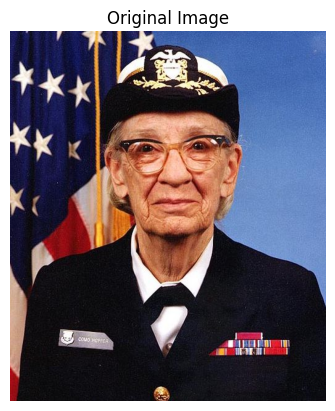

In [8]:

# Load a built-in sample image
from matplotlib import cbook

image = plt.imread(cbook.get_sample_data("grace_hopper.jpg"))

print("Image shape:", image.shape)

plt.imshow(image)
plt.title("Original Image")
plt.axis("off")
plt.show()


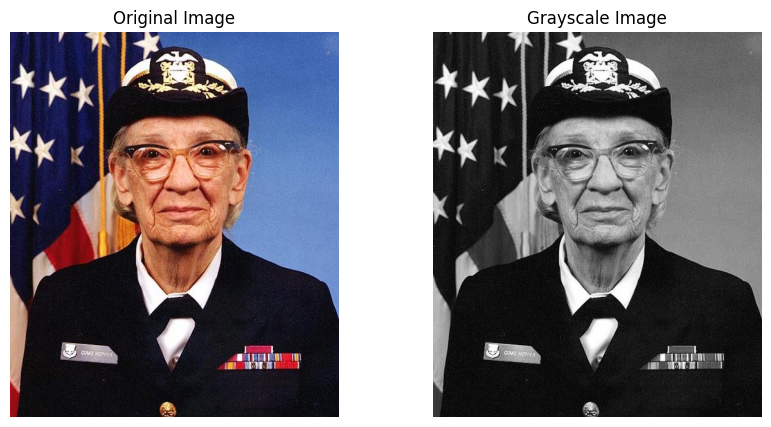

In [9]:

# Convert RGB image to grayscale using NumPy broadcasting

gray = np.dot(image[..., :3], [0.2989, 0.5870, 0.1140])

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.show()


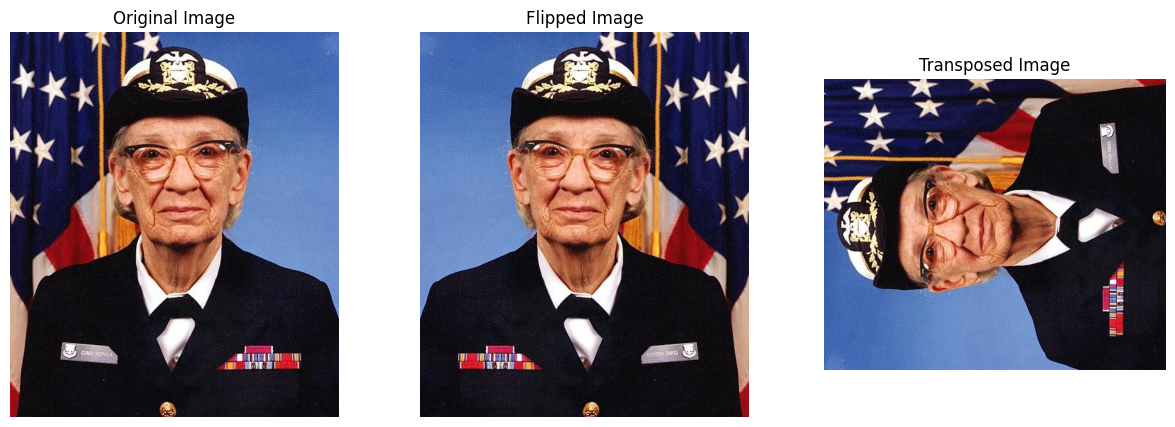

In [10]:

# Flip and rotate the image using NumPy

flipped = np.flip(image, axis=1)
rotated = np.transpose(image, (1, 0, 2))

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(flipped)
plt.title("Flipped Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(rotated)
plt.title("Transposed Image")
plt.axis("off")

plt.show()


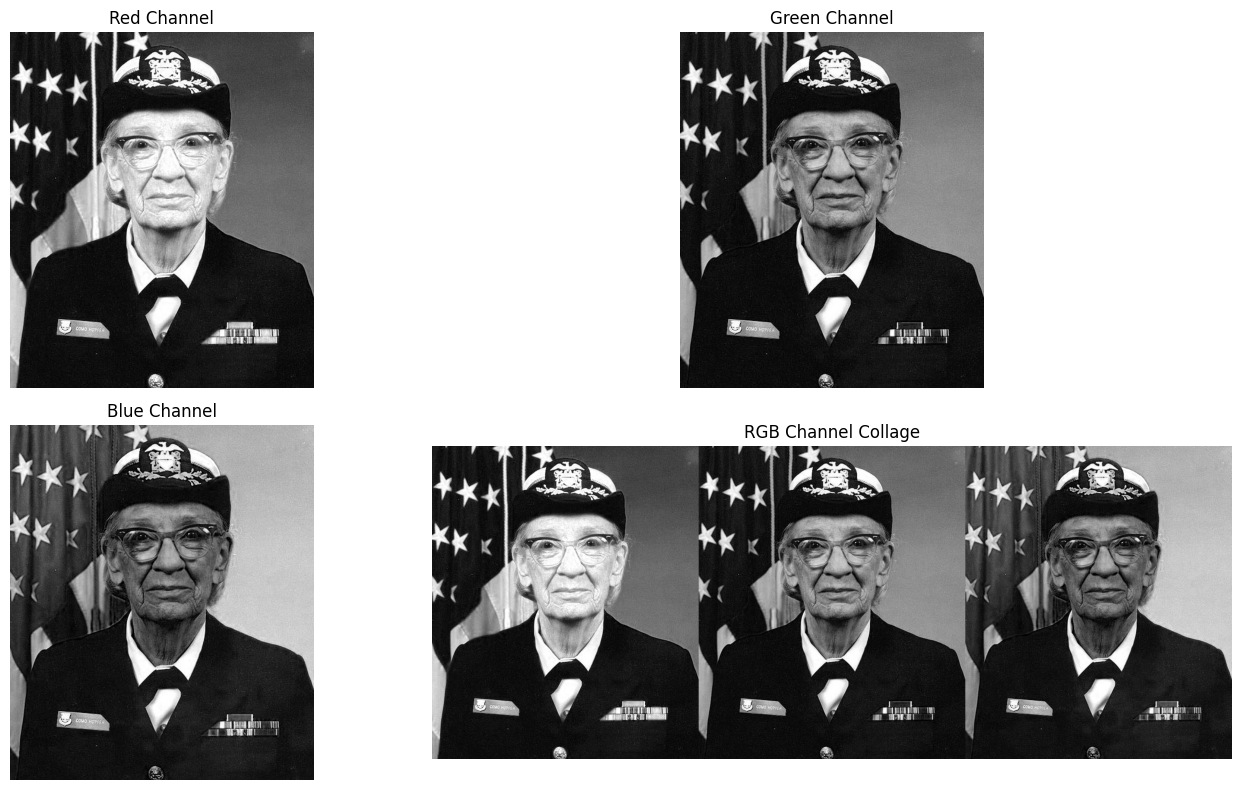

Red channel shape: (600, 512)
Green channel shape: (600, 512)
Blue channel shape: (600, 512)
Collage shape: (600, 1536)


In [11]:

# Split the RGB channels
red = image[:, :, 0]
green = image[:, :, 1]
blue = image[:, :, 2]

# Create a collage using NumPy stacking
collage = np.hstack((red, green, blue))

# Display the channels and collage
plt.figure(figsize=(15, 8))

plt.subplot(2, 2, 1)
plt.imshow(red, cmap="gray")
plt.title("Red Channel")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(green, cmap="gray")
plt.title("Green Channel")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(blue, cmap="gray")
plt.title("Blue Channel")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(collage, cmap="gray")
plt.title("RGB Channel Collage")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Red channel shape:", red.shape)
print("Green channel shape:", green.shape)
print("Blue channel shape:", blue.shape)
print("Collage shape:", collage.shape)


Pixel loop performance:
1.9 s ± 303 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)

NumPy performance:
5.27 ms ± 1.69 ms per loop (mean ± std. dev. of 5 runs, 3 loops each)


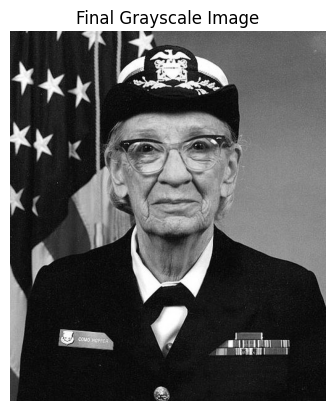

In [12]:

# Method 1: Process pixels using loops
def grayscale_loop(img):
    height, width, _ = img.shape
    result = np.zeros((height, width))

    for i in range(height):
        for j in range(width):
            result[i, j] = (
                0.2989 * img[i, j, 0]
                + 0.5870 * img[i, j, 1]
                + 0.1140 * img[i, j, 2]
            )

    return result


# Method 2: Process all pixels using NumPy
def grayscale_numpy(img):
    return np.dot(img[..., :3], [0.2989, 0.5870, 0.1140])


# Benchmark both methods
print("Pixel loop performance:")
%timeit -n 1 -r 3 grayscale_loop(image)

print("\nNumPy performance:")
%timeit -n 3 -r 5 grayscale_numpy(image)


# Display final grayscale result
plt.imshow(grayscale_numpy(image), cmap="gray")
plt.title("Final Grayscale Image")
plt.axis("off")
plt.show()


# New section